- Para instalar os pacotes, caso não tenha:

In [ ]:
!pip install seaborn, matplotlib

- Importar as bibliotecas:

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Exemplo 1

- Importe o banco de dados `Atividade1.csv`, depois:

a) Faça um gráfico de boxplot e um histograma das variáveis `idade` e `salario`.

b) Faça um gráfico de setor e um de barras com a variável `emprego`.

c) Faça um gráfico de dispersão com as variáveis `idade` e `salario`.

d) Faça um boxplot com as variáveis `idade` e `emprego`, e outro com as variáveis `salario` e `emprego`.

e) Modifque cor, texto e/ou dos gráficos acima.

In [ ]:
df1 = pd.read_csv('/content/Atividade1.csv', sep =',')
df1.columns = df1.columns.str.strip()
print(df1.columns.tolist())
df1.head()

['Empregado', 'salario', 'idade', 'emprego']


,Empregado,salario,idade,emprego
0,1,41.200,45,2
1,2,39.565,43,1
2,3,30.980,41,1
3,4,23.225,27,1
4,5,21.250,26,1


In [ ]:
# Tabela de frequencia por classes
df1['classes_salario'] = pd.cut(df1['salario'], bins=5)  # 5 classes de tamanhos iguais

freq_auto = df1['classes_salario'].value_counts().sort_index()
print("=" * 50)
print("Tabela de frequência por classes (5 CLASSES)")
print("=" * 50)
print(freq_auto)

Tabela de frequência por classes (5 CLASSES)
classes_salario
(19.409, 24.543]     7
(24.543, 29.651]     3
(29.651, 34.759]     6
(34.759, 39.867]     4
(39.867, 44.975]    10
Name: count, dtype: int64


In [ ]:
# assimetria
print("Assimetria:")
ass_sal = df1['salario'].skew()
print(round(ass_sal, 2))
ass_ida = df1['idade'].skew()
print(round(ass_ida, 2))
print("")
# curtose
print("Curtose:")
cur_sal = df1['salario'].kurtosis()
print(round(cur_sal, 2))
cur_ida = df1['idade'].kurtosis()
print(round(cur_ida, 2))

Assimetria:
-0.11
-0.3

Curtose:
-1.58
-1.22


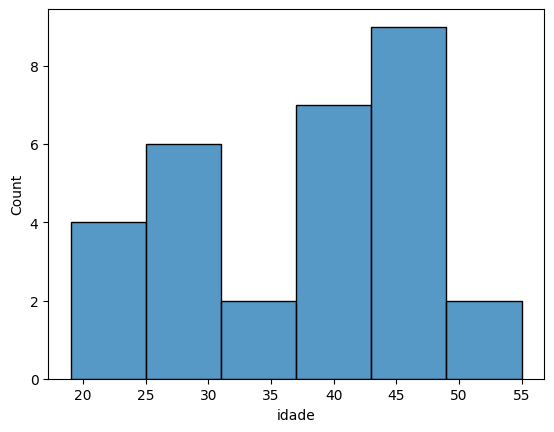

In [ ]:
# a) histograma de idade
sns.histplot(x='idade', data=df1)
plt.show()

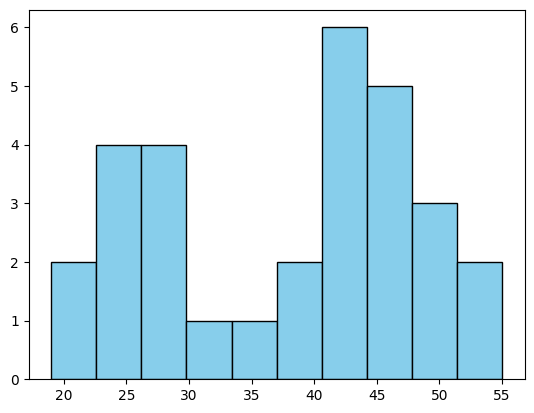

In [ ]:
plt.hist(df1['idade'], bins=10, color='skyblue', edgecolor='black')
plt.show()

In [ ]:
# histograma do salario

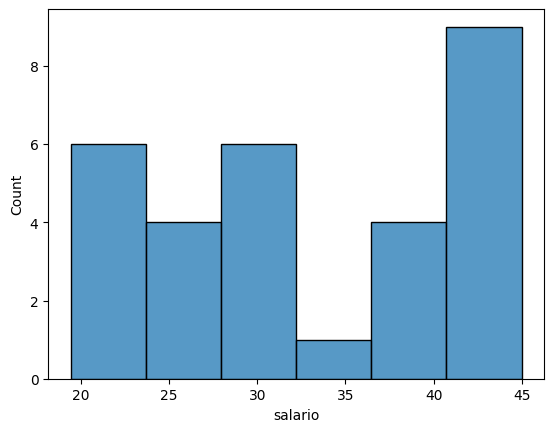

In [ ]:
sns.histplot(x='salario', data=df1)
plt.show()

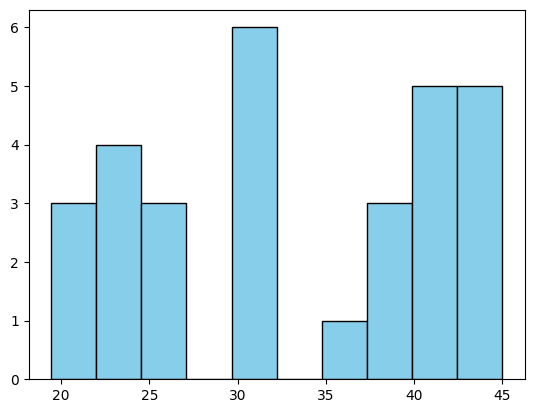

In [ ]:
plt.hist(df1['salario'], bins=10, color='skyblue', edgecolor='black')
plt.show()

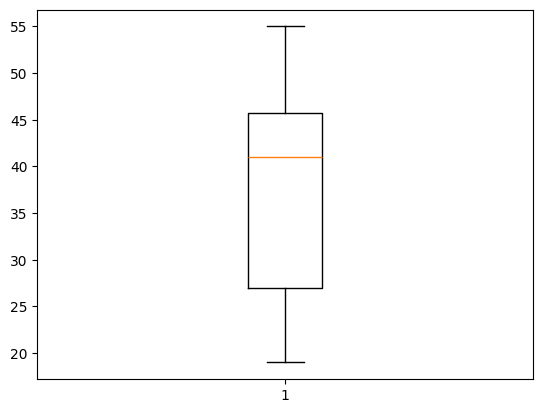

In [ ]:
# boxplot de idade
plt.boxplot(df1['idade'])
plt.show()

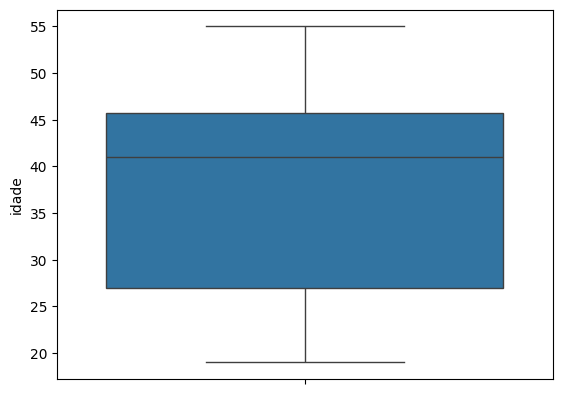

In [ ]:
sns.boxplot(df1['idade'])
plt.show()

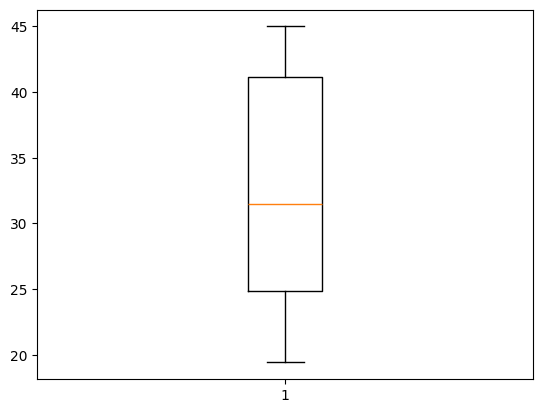

In [ ]:
# boxplot de salario
plt.boxplot(df1['salario'])
plt.show()

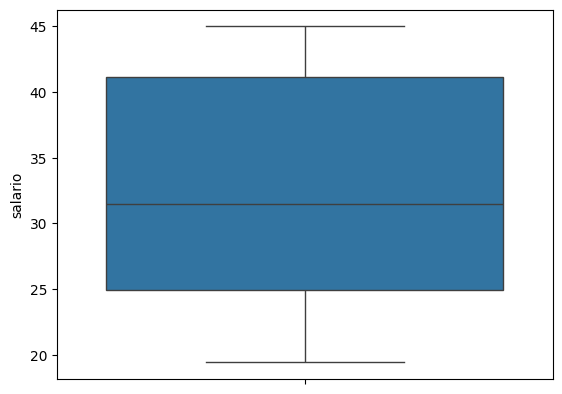

In [ ]:
sns.boxplot(df1['salario'])
plt.show()

b) Faça um gráfico de setor e um de barras com a variável `emprego`.

Primeiro, vamos transformar a variável emprego em um fator, em que `1 - demitido`, `2 - ativo`.

In [ ]:
# Método 1: Usando apply
#df1['emprego2'] = df1['emprego'].apply(lambda x: 'demitido' if x == 1 else 'ativo')

# Método 2: Usando map
#df1['emprego2'] = df1['emprego'].map({1: 'demitido', 0: 'ativo'})
# Veja todas as colunas do seu DataFrame

# Método 3: Usando .loc
df1['emprego2'] = 'ativo'
df1.loc[df1['emprego'] == 1, 'emprego2'] = 'demitido'
print(df1.head())

   Empregado  salario  idade  emprego   classes_salario  emprego2
0          1   41.200     45        2  (39.867, 44.975]     ativo
1          2   39.565     43        1  (34.759, 39.867]  demitido
2          3   30.980     41        1  (29.651, 34.759]  demitido
3          4   23.225     27        1  (19.409, 24.543]  demitido
4          5   21.250     26        1  (19.409, 24.543]  demitido


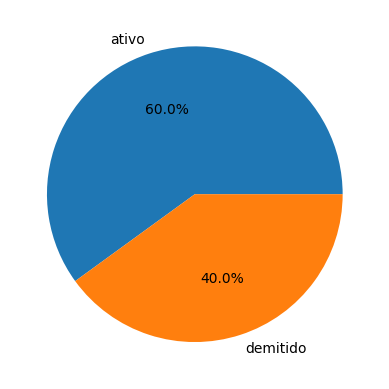

In [ ]:
# setor
plt.pie(df1['emprego2'].value_counts(), labels = df1['emprego2'].unique(), autopct='%1.1f%%')
plt.show()

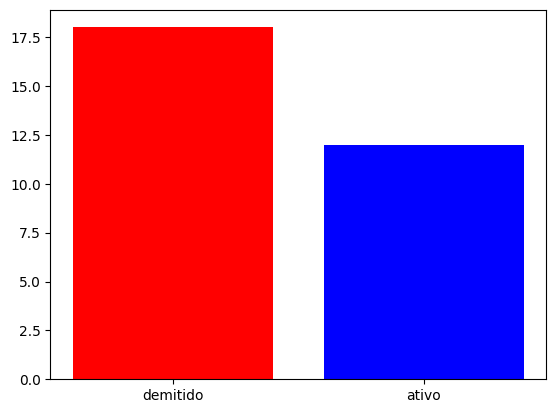

In [ ]:
# barras
graf_barras = df1['emprego2'].value_counts()
plt.bar(graf_barras.index, graf_barras, color = ['red', 'blue'])
plt.show()

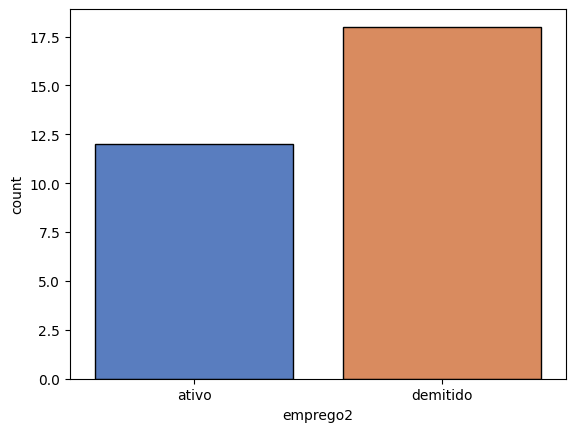

In [ ]:
sns.countplot(x='emprego2', data=df1, hue='emprego2', palette='muted', edgecolor='black')
plt.show()


c) Faça um gráfico de dispersão com as variáveis `idade` e `salario`.

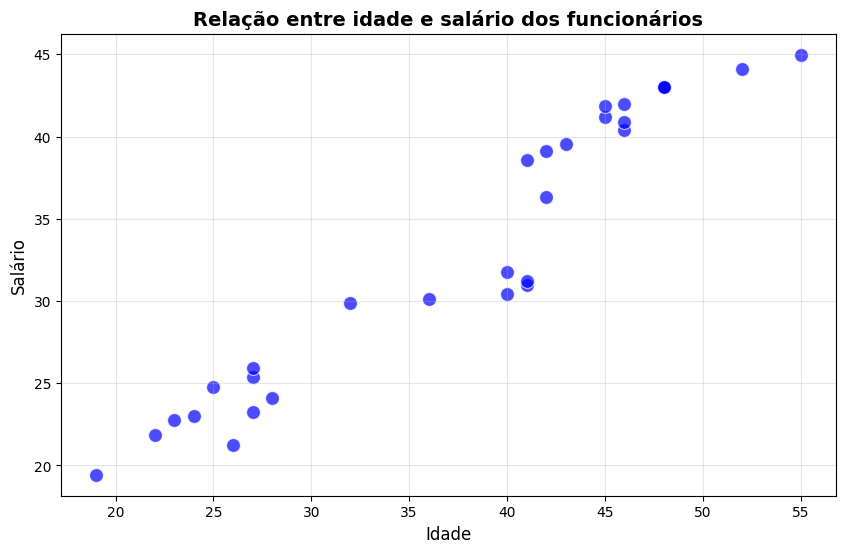

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='idade', y='salario', data=df1, color='blue', s=100, alpha=0.7)
plt.title('Relação entre idade e salário dos funcionários', fontsize=14,fontweight='bold')
plt.xlabel('Idade', fontsize=12)
plt.ylabel('Salário', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

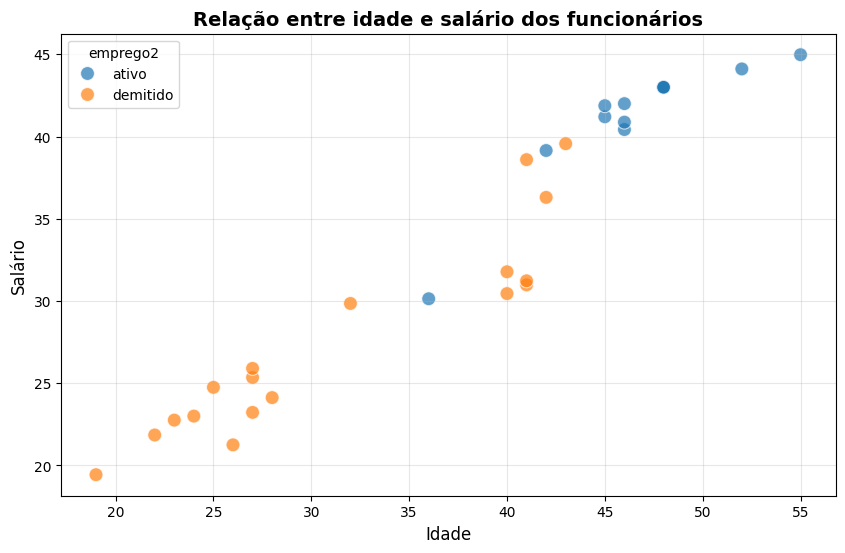

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='idade', y='salario', data=df1, hue='emprego2', s=100, alpha=0.7)
plt.title('Relação entre idade e salário dos funcionários', fontsize=14,fontweight='bold')
plt.xlabel('Idade', fontsize=12)
plt.ylabel('Salário', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()


d) Faça um boxplot com as variáveis `idade` e `emprego`, e outro com as variáveis `salario` e `emprego`.

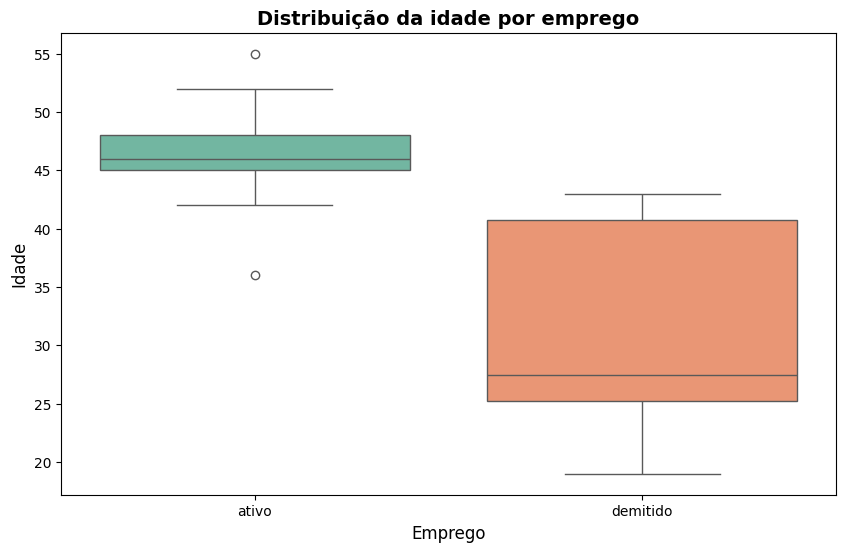

In [ ]:
# idade e emprego
plt.figure(figsize=(10, 6))
sns.boxplot(x='emprego2', y='idade', hue='emprego2', data=df1, palette='Set2')
plt.title('Distribuição da idade por emprego', fontsize=14,fontweight='bold')
plt.xlabel('Emprego', fontsize=12)
plt.ylabel('Idade', fontsize=12)
plt.show()

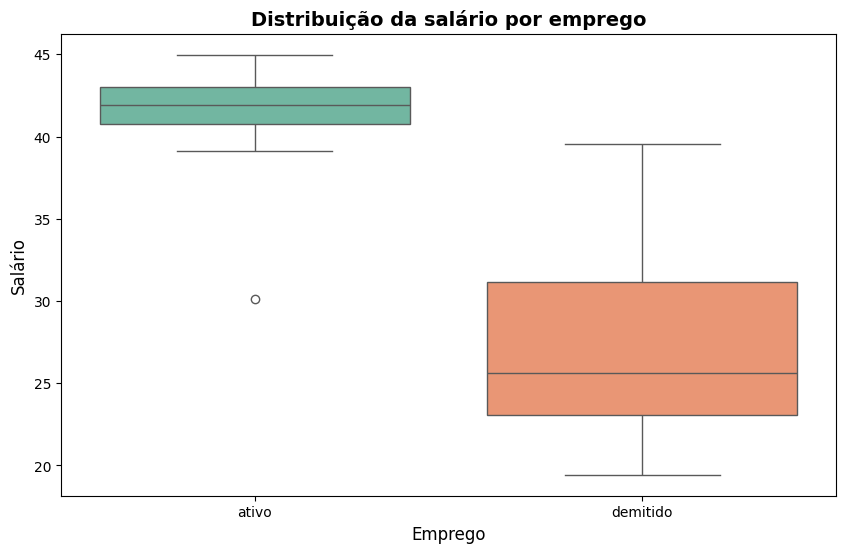

In [ ]:
# salario e emprego
plt.figure(figsize=(10, 6))
sns.boxplot(x='emprego2', y='salario', hue='emprego2', data=df1, palette='Set2')
plt.title('Distribuição da salário por emprego', fontsize=14,fontweight='bold')
plt.xlabel('Emprego', fontsize=12)
plt.ylabel('Salário', fontsize=12)
plt.show()

e) Modifque cor, texto e/ou dos gráficos acima.

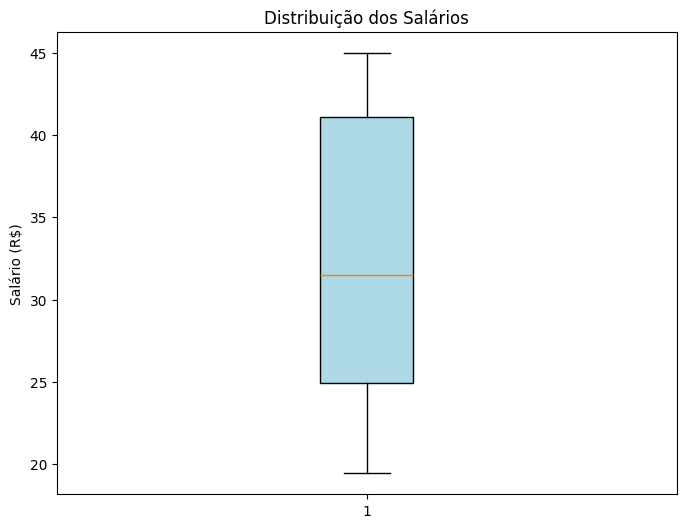

In [ ]:
# boxplot de salario
plt.figure(figsize=(8, 6))
plt.boxplot(df1['salario'],patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('Distribuição dos Salários')
plt.ylabel('Salário (R$)')
plt.show()

# Atividade 1

- Importe o banco de dados dos `penguins` da biblioteca `seaborn`:

```
import seaborn as sns
import pandas as pd

# Carrega o dataset dos pinguins
df_pinguins = sns.load_dataset('penguins')
print(df_pinguins.head())
```

1. **Carregue e explore os dados:** Use métodos como `info()` e `describe()` para conhecer as variáveis.

2. **Analise a distribuição:** Faça um histograma (`sns.histplot`) do peso (`body_mass_g`) e um boxplot (`sns.boxplot`) do comprimento do bico separado por espécie.

3. **Crie um gráfico de dispersão:** Plote o `bill_length_mm` (comprimento do bico) no eixo X e o `bill_depth_mm` (profundidade do bico) no eixo Y, colorindo os pontos por `species` (espécie). Use `sns.scatterplot` ou `sns.pairplot`.